# Step 4a — How much of our ground truth does Dolphin actually find?

Dolphin (run zero-shot, no fine-tuning) detects almost everything on a
page -- including things we don't want, like a sub-panel or sub-table
nested inside a figure we only labelled as one box. Before deciding how
to use it, the question worth answering first is **recall**: of every box
we hand-labelled (Table / Plot / Diagram / Figure_Mixed), how many does
Dolphin find *at all*, regardless of the label it gives them or how many
extra boxes it also draws?

If recall comes out ~100%, over-detection stops being a problem to fix at
the detector level -- it becomes something a small classifier head can
clean up afterwards (keep only the boxes that look like our 4 classes,
drop the rest), which is much cheaper than fine-tuning a detector from
scratch. If recall is lower than that, we know which class(es) Dolphin is
actually missing and can look at *why* before committing to that plan.

**Matching rule** (see `step04a_measure_dolphin_recall.py` for the full
rationale): a ground-truth box counts as *found* if the single
best-matching Dolphin box on that page clears either
- IoU >= `IOU_THRESHOLD` (well-aligned boxes), or
- containment(ground-truth box, Dolphin box) >= `CONTAINMENT_THRESHOLD`
  (most of our box's area is covered by one Dolphin box, even if that
  Dolphin box is bigger because it grabbed a whole composite region)

**Before running this**: run `Dolphin_Inference.ipynb` first (same folder)
so `dolphin_results/dolphin_flat.csv` exists -- this notebook reads that
file rather than re-running the model.

**Folder layout this notebook expects:**
```
2026/
  My_code/
    step03_labelbox_export/
    step04_detection/
      01_dolphin_baseline/    <- this notebook + dolphin_flat.csv live here
      02_doclayout_yolo_finetune/
  Pre-Pages-2Annotate/         <- ndjson export + topic image folders
```


In [1]:
# Locate the project from either the project root or a notebook directory.
import os
import sys
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "Pre-Pages-2Annotate").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "My_code"))
from annotation_inputs import latest_annotation_export, annotated_image_paths, build_image_index
os.chdir(PROJECT_ROOT / 'My_code/step04_detection/01_dolphin_baseline')
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import step04a_measure_dolphin_recall as recall

ANNOTATIONS_ROOT = PROJECT_ROOT / "Pre-Pages-2Annotate" / "Exported_annotated_data"
NDJSON_PATH = latest_annotation_export(ANNOTATIONS_ROOT)
print(f"Annotation export: {NDJSON_PATH.name}")
IMAGES_ROOT = Path("../../../Pre-Pages-2Annotate")
DOLPHIN_CSV = Path("./dolphin_results/dolphin_flat.csv")

IOU_THRESHOLD = 0.5
CONTAINMENT_THRESHOLD = 0.8

assert NDJSON_PATH.exists(), f"Export not found at {NDJSON_PATH.resolve()}"
assert IMAGES_ROOT.exists(), f"Images root not found at {IMAGES_ROOT.resolve()}"
assert DOLPHIN_CSV.exists(), (
    f"{DOLPHIN_CSV.resolve()} not found -- run Dolphin_Inference.ipynb first "
    f"so dolphin_flat.csv exists."
)
print("Paths OK.")


Annotation export: Export  project - STEPS-Paper-Annotation - 9_23_2026.ndjson
Paths OK.


## Run the comparison

Ground truth comes from the same box-resolution logic as the YOLO/Docling
fine-tuning dataset (a `Figure_Mixed` composite's outer box, nested
Plot/Diagram sub-boxes excluded) -- so this is directly comparable to
"can Dolphin replace/seed that dataset".


In [2]:
result = recall.measure_recall(
    ndjson_path=NDJSON_PATH,
    images_root=IMAGES_ROOT,
    dolphin_csv_path=DOLPHIN_CSV,
    iou_threshold=IOU_THRESHOLD,
    containment_threshold=CONTAINMENT_THRESHOLD,
)
recall_table = result["recall_table"]


──────────────────────────────────────────────────────
Pages with ground truth: 267
Pages Dolphin was run on (found in dolphin_flat.csv): 267

Match thresholds: IoU >= 0.5  OR  containment(gt in det) >= 0.8

  class_name  n_boxes  n_matched   recall
     Diagram       57         57 1.000000
Figure_Mixed       16         16 1.000000
        Plot       71         71 1.000000
       Table       71         70 0.985915
         ALL      215        214 0.995349

1 ground-truth box(es) Dolphin did NOT find:
    - Biosorption-of-copper-ions-through-microalgae-from-pigge_2021_Journal-of-Cle_page_0002.png  [Table]  best_iou=0.405  best_containment=0.405  best_dolphin_label=tab


## Recall by class

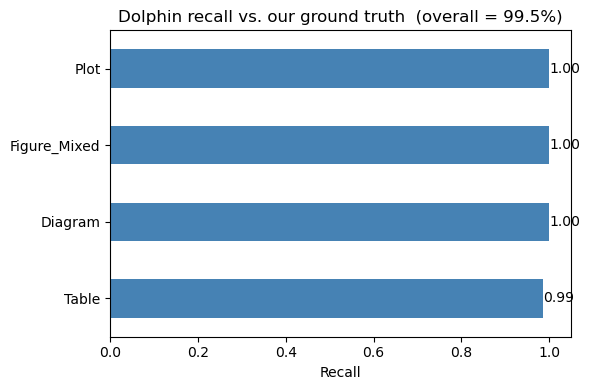

In [3]:
import matplotlib.pyplot as plt

plot_df = recall_table[recall_table["class_name"] != "ALL"].sort_values("recall")
ax = plot_df.plot(x="class_name", y="recall", kind="barh", figsize=(6, 4),
                   color="steelblue", legend=False)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Recall")
ax.set_ylabel("")
ax.bar_label(ax.containers[0], fmt="%.2f")
overall = recall_table.loc[recall_table["class_name"] == "ALL", "recall"].iloc[0]
ax.set_title(f"Dolphin recall vs. our ground truth  (overall = {overall:.1%})")
plt.tight_layout()
plt.show()


## If recall is ~100%: next step is a classifier head, not more detection

At that point Dolphin (or any zero-shot layout model) is already finding
the *regions* we care about -- the remaining work is purely
classification: given a Dolphin-proposed box, is it one of our 4 wanted
classes (and if so which), or is it one of the many other things Dolphin
also detects (headings, equations, running text blocks, a sub-panel
that's part of a bigger figure we already caught, etc.)?

The cell below breaks down what Dolphin's *matched* boxes were labelled
as -- this tells us how many wanted classes vs. distractor classes a
classifier head would actually have to sort between.


In [4]:
import pandas as pd

records_df = pd.DataFrame(result["records"])
matched_df = records_df[records_df["matched"]]
print("Dolphin's own label on our matched ground-truth boxes:")
print(matched_df["best_dolphin_label"].value_counts())

print(f"\nAll labels Dolphin assigned on these {len(result['pages'])} page(s) "
      f"(matched + unmatched, i.e. every box it drew):")
all_labels = pd.Series(
    [d["label"] for dets in result["detections_by_image"].values() for d in dets]
)
print(all_labels.value_counts())


Dolphin's own label on our matched ground-truth boxes:
best_dolphin_label
fig    143
tab     70
equ      1
Name: count, dtype: int64

All labels Dolphin assigned on these 267 page(s) (matched + unmatched, i.e. every box it drew):
reference    1863
para         1260
header        572
sec_1         220
cap           213
sec_2         212
fig           203
foot          187
half_para     172
sec_3          91
fnote          85
tab            74
equ            67
anno           35
sec_0          20
list           11
catalogue       5
Name: count, dtype: int64


## Ground-truth boxes Dolphin missed

Empty output below means 100% recall at these thresholds -- nothing to look at. Otherwise, each missed box is shown with the ground-truth box in **green** and Dolphin's closest (but not close enough) box in **red**, so it's easy to see whether it's a true miss or just a borderline threshold call.

1 missed box(es).


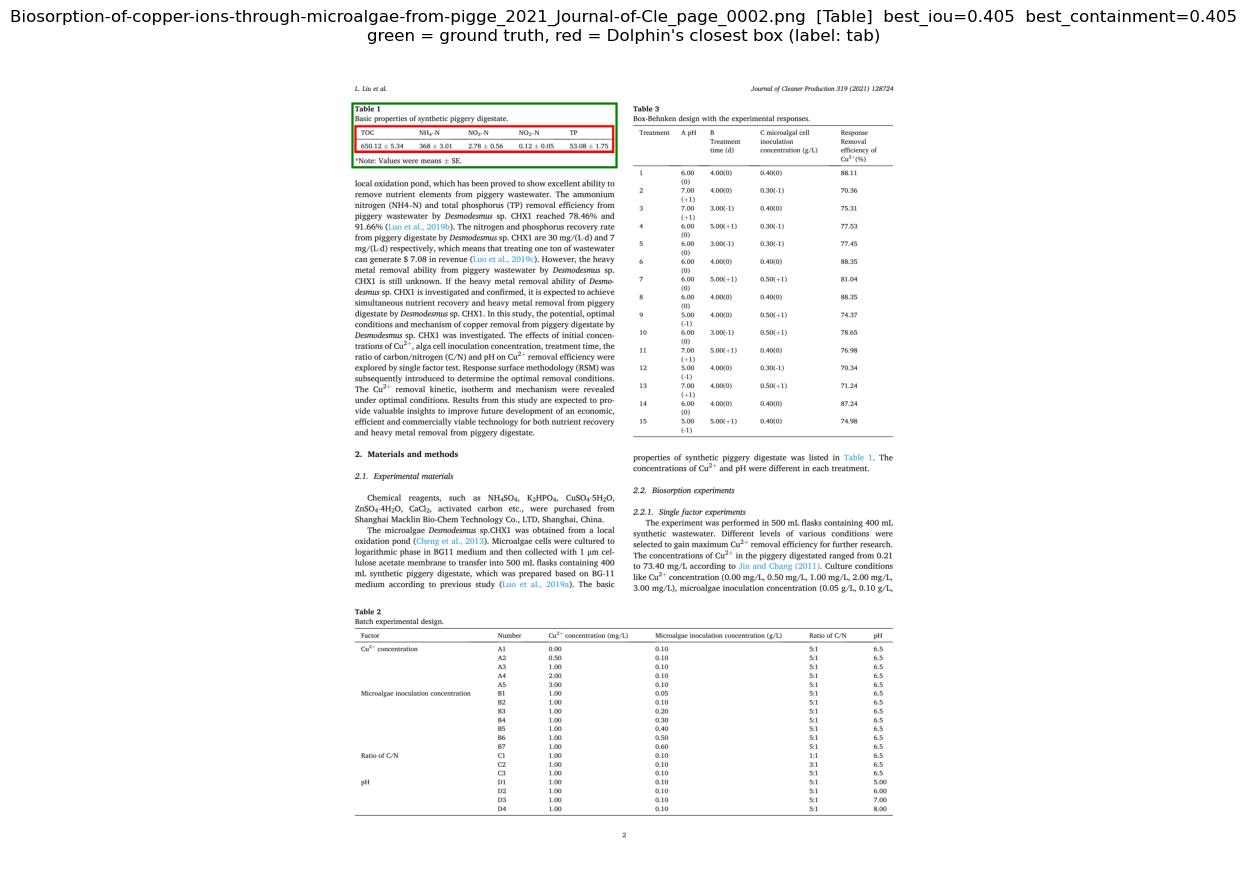

In [5]:
from PIL import Image, ImageDraw

missed = result["missed"]
print(f"{len(missed)} missed box(es).")

for m in missed[:8]:
    img_path = None
    for page in result["pages"]:
        if page["external_id"] == m["image"]:
            img_path = page["local_path"]
            break
    if img_path is None or not Path(img_path).exists():
        print(f"(image not found locally for {m['image']}, skipping visual)")
        continue

    img = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(img)

    gl, gt_, gw, gh = m["gt_box"]
    draw.rectangle([gl, gt_, gl + gw, gt_ + gh], outline="green", width=6)

    if m["best_dolphin_box"] is not None:
        dl, dt, dw, dh = m["best_dolphin_box"]
        draw.rectangle([dl, dt, dl + dw, dt + dh], outline="red", width=6)

    plt.figure(figsize=(8, 8 * img.size[1] / img.size[0]))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{m['image']}  [{m['class_name']}]  "
              f"best_iou={m['best_iou']}  best_containment={m['best_containment']}\n"
              f"green = ground truth, red = Dolphin's closest box "
              f"(label: {m['best_dolphin_label']})")
    plt.show()


## Save the full per-box match table

One row per ground-truth box: matched or not, best IoU/containment score,
and which Dolphin box/label it matched against -- useful for digging into
specific pages later, or for re-running this with different thresholds
without recomputing everything.


In [6]:
OUTPUT_CSV = Path("./dolphin_recall.csv")
pd.DataFrame(result["records"]).to_csv(OUTPUT_CSV, index=False)
print(f"Saved {len(result['records'])} row(s) to {OUTPUT_CSV.resolve()}")


Saved 215 row(s) to /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/01_dolphin_baseline/dolphin_recall.csv
